# 从零实现 Transformer：数字序列反转

**任务**：输入一串 3–10 位数字，模型输出它的倒序。

```
输入 : 3 7 1 9 4 6 0 8
输出 : 8 0 6 4 9 1 7 3
```

**为什么选这个任务**：答案唯一、可以无限生成数据，而且"反转"在注意力上有一个明确的预期形状（反对角线），方便检查模型到底学到了什么。

**本 notebook 的顺序**：
1. 搭模型：多头注意力 → 前馈层 → 编码器/解码器层 → 位置编码 → 整体模型
2. 造数据、训练、测准确率
3. 三张图：loss 曲线、注意力热力图、3D loss 地形 + 训练轨迹

> 简化说明：这是教学用的小模型（约 17 万参数），结构按论文原版 post-LN，但没有 KV cache、beam search 等工程优化。

搭建

In [2]:

import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils import parameters_to_vector, vector_to_parameters

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu128


## 1. 多头注意力（Multi-Head Attention）

核心公式（论文 Eq. 1）：

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- **Q（query）**：“我现在要找什么”。**K（key）**：“我这里有什么”。**V（value）**：“找到后真正拿走的内容”。
- `scores[i, j]` = 第 i 个 query 和第 j 个 key 的匹配程度。除以 $\sqrt{d_k}$ 是为了防止数值太大、softmax 过于尖锐。
- **多头**：把 `d_model` 切成 `heads` 份，每份独立做注意力，最后拼回去。不同的头可以关注不同的东西。

形状变化（B=batch，n=序列长度，h=头数，d_k=每头维度）：
`[B, n, d_model]` → `split` → `[B, h, n, d_k]` → 注意力 → 拼回 `[B, n, d_model]`

两种 mask（`True` = 不许看）：
- **causal mask**：解码器第 i 步不能偷看第 i 步之后的答案（上三角被屏蔽）。
- **padding mask**：补齐用的 PAD 不是真实内容，不让任何 query 去看它。

`self.last_weights` 把注意力权重存下来，第 6 节画热力图要用。

In [3]:
class MultiHead(nn.Module):
    """Batch-first; Boolean masks use True = blocked."""
    def __init__(self, d_model, heads, dropout=0.1):
        super().__init__()
        if d_model % heads:
            raise ValueError("d_model must be divisible by heads")
        self.heads, self.dk = heads, d_model // heads
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def split(self, x):
        b, n, _ = x.shape
        return x.reshape(b, n, self.heads, self.dk).transpose(1, 2)

    def forward(self, query, key, value, *, causal=False, key_pad=None):
        # query [B,m,d], key/value [B,n,d]; m can differ from n.
        q, k, v = self.split(self.q_proj(query)), self.split(self.k_proj(key)), self.split(self.v_proj(value))
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dk)
        m, n = scores.shape[-2:]
        if causal:
            if m != n:
                raise ValueError("This simple causal path expects equal lengths; no KV cache.")
            future = torch.ones(m, n, device=scores.device, dtype=torch.bool).triu(1)
            scores = scores.masked_fill(future, float("-inf"))
        if key_pad is not None:
            scores = scores.masked_fill(key_pad[:, None, None, :], float("-inf"))
        # Do not silently generate NaN for an entirely masked query.
        if torch.isneginf(scores).all(dim=-1).any():
            raise ValueError("Every query must have at least one allowed key.")
        weights = scores.softmax(dim=-1)
        self.last_weights = weights.detach()   # kept for the heatmap
        out = self.dropout(weights) @ v
        b = out.size(0)
        out = out.transpose(1, 2).contiguous().reshape(b, m, self.heads * self.dk)
        return self.out_proj(out)

**小检查**：随机输入过一遍，确认输出形状不变、每行注意力权重加起来等于 1。

In [4]:
attn = MultiHead(d_model=8, heads=2, dropout=0.0)
x = torch.randn(1, 5, 8)
y = attn(x, x, x, causal=True)
print("output shape:", tuple(y.shape))
print("row sums:", attn.last_weights.sum(-1)[0, 0])
print("head 0 weights (upper triangle should be 0 because of the causal mask):")
print(attn.last_weights[0, 0].round(decimals=2))

output shape: (1, 5, 8)
row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
head 0 weights (upper triangle should be 0 because of the causal mask):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7600, 0.2400, 0.0000, 0.0000, 0.0000],
        [0.3600, 0.2800, 0.3600, 0.0000, 0.0000],
        [0.2200, 0.3300, 0.2300, 0.2300, 0.0000],
        [0.2400, 0.1200, 0.2800, 0.1800, 0.1700]])


## 2. 前馈层（Feed-Forward）

对每个位置**单独**做两层全连接：`d_model → d_ff → d_model`，中间用 ReLU。
注意力负责“位置之间交换信息”，前馈层负责“每个位置自己加工信息”。

In [5]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.first = nn.Linear(d_model, d_ff)
        self.second = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.second(F.relu(self.first(x)))

## 3. 编码器层和解码器层

每个子层都套一个 **残差 + LayerNorm**：`x = LayerNorm(x + Dropout(子层(x)))`。这是论文原版的 **post-LN** 写法（现在的大模型多用 pre-LN，训练更稳）。

| | 子层 1 | 子层 2 | 子层 3 |
|---|---|---|---|
| 编码器 | 自注意力（看整个输入） | 前馈 | — |
| 解码器 | **带 causal mask** 的自注意力（只看已生成部分） | **交叉注意力**：Q 来自解码器，K/V 来自编码器输出 `memory` | 前馈 |

交叉注意力就是“解码器去查输入序列”的地方，第 6 节的热力图画的就是它。

In [11]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, heads, d_ff, dropout):
        super().__init__()
        self.attn = MultiHead(d_model, heads, dropout)
        self.ffn = FeedForward(d_model, d_ff)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, src_pad):
        x = self.norm1(x + self.drop(self.attn(x, x, x, key_pad=src_pad)))
        return self.norm2(x + self.drop(self.ffn(x)))


class DecoderLayer(nn.Module):
    def __init__(self, d_model, heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHead(d_model, heads, dropout)
        self.cross_attn = MultiHead(d_model, heads, dropout)
        self.ffn = FeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, src_pad, tgt_pad):
        x = self.norm1(x + self.drop(self.self_attn(
            x, x, x, causal=True, key_pad=tgt_pad)))
        x = self.norm2(x + self.drop(self.cross_attn(
            x, memory, memory, key_pad=src_pad)))
        return self.norm3(x + self.drop(self.ffn(x)))

## 4. 正弦位置编码（Sinusoidal Position）

注意力本身不知道顺序：把输入打乱，每个位置得到的结果只是跟着换位置。所以要把“我在第几位”加进向量里。

$$PE_{(pos,2i)}=\sin\!\left(pos/10000^{2i/d}\right),\quad PE_{(pos,2i+1)}=\cos\!\left(pos/10000^{2i/d}\right)$$

低维度变化快（像秒针），高维度变化慢（像时针），组合起来每个位置都有独一无二的“指纹”。
对“反转”任务，位置信息尤其关键：模型必须知道“第 1 个输出对应最后一个输入”。

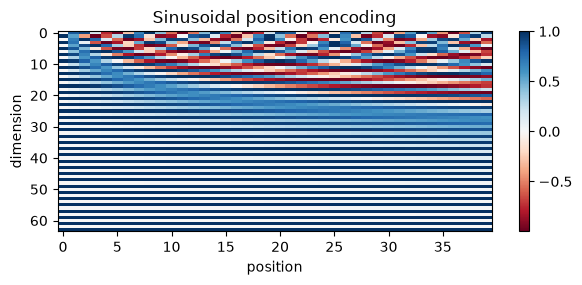

In [10]:
class SinusoidalPosition(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        if d_model % 2:
            raise ValueError("This educational implementation uses even d_model.")
        pos = torch.arange(max_len).float().unsqueeze(1)
        inverse_scale = torch.exp(torch.arange(0, d_model, 2).float()
                                  * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * inverse_scale)
        pe[:, 1::2] = torch.cos(pos * inverse_scale)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        if x.size(1) > self.pe.size(1):
            raise ValueError("Sequence exceeds the configured positional buffer.")
        return x + self.pe[:, :x.size(1)].to(dtype=x.dtype)


pe = SinusoidalPosition(64).pe[0, :40]
plt.figure(figsize=(7, 2.6))
plt.imshow(pe.T, aspect="auto", cmap="RdBu")
plt.xlabel("position"); plt.ylabel("dimension"); plt.title("Sinusoidal position encoding")
plt.colorbar(); plt.show()

## 5. 组装完整模型 + 学习率调度

流程：`token id → 词向量 × √d_model → 加位置编码 → N 层编码器 → memory`；
`目标前缀 → 同样嵌入 → N 层解码器（查 memory）→ 线性层 → 每个词的分数（logits）`。

- **权重共享（tied embeddings）**：输出层和词向量用同一个矩阵，参数更少。
- 输出的是 **logits**，不是概率；`cross_entropy` 内部自己做 softmax。
- **学习率调度**（论文 Eq. 3）：前 `warmup` 步线性升高，之后按 $1/\sqrt{step}$ 下降。

$$lr = d_{model}^{-0.5}\cdot\min(step^{-0.5},\ step\cdot warmup^{-1.5})$$

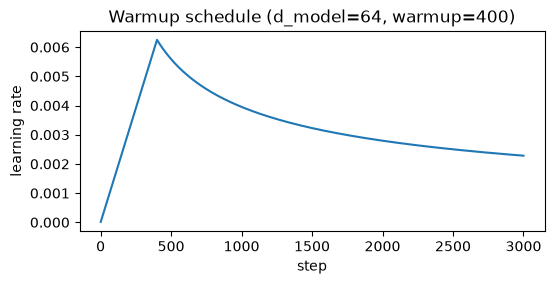

In [12]:
class Transformer(nn.Module):
    """Shared source/target vocabulary. PAD=0; each source must be nonempty."""
    def __init__(self, vocab_size, d_model=32, heads=4, d_ff=64,
                 layers=2, dropout=0.1, pad_id=0):
        super().__init__()
        self.pad_id, self.scale = pad_id, math.sqrt(d_model)
        # Intentionally no padding_idx: tied output weights include all tokens.
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.position = SinusoidalPosition(d_model)
        self.drop = nn.Dropout(dropout)
        self.encoders = nn.ModuleList([
            EncoderLayer(d_model, heads, d_ff, dropout) for _ in range(layers)])
        self.decoders = nn.ModuleList([
            DecoderLayer(d_model, heads, d_ff, dropout) for _ in range(layers)])
        self.output = nn.Linear(d_model, vocab_size, bias=False)
        self.output.weight = self.embedding.weight
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def embed(self, ids):
        return self.drop(self.position(self.embedding(ids) * self.scale))

    def forward(self, src, tgt_in):
        src_pad, tgt_pad = src.eq(self.pad_id), tgt_in.eq(self.pad_id)
        memory = self.embed(src)
        for layer in self.encoders:
            memory = layer(memory, src_pad)
        x = self.embed(tgt_in)
        for layer in self.decoders:
            x = layer(x, memory, src_pad, tgt_pad)
        return self.output(x)  # logits, NOT softmax probabilities


def learning_rate(step, d_model=512, warmup=4000):
    if step < 1 or warmup < 1:
        raise ValueError("step and warmup must be positive")
    return d_model ** -0.5 * min(step ** -0.5, step * warmup ** -1.5)


steps = range(1, 3001)
plt.figure(figsize=(6, 2.6))
plt.plot(steps, [learning_rate(s, 64, 400) for s in steps])
plt.xlabel("step"); plt.ylabel("learning rate"); plt.title("Warmup schedule (d_model=64, warmup=400)")
plt.show()

## 6. 造数据

词表一共 13 个 token：

| id | 0 | 1 | 2 | 3–12 |
|---|---|---|---|---|
| 含义 | PAD（补齐） | BOS（开始） | EOS（结束） | 数字 0–9 |

一条样本：源序列 `3 7 1 9`，目标序列 `BOS 9 1 7 3 EOS`，长度不够就在右边补 PAD。

**Teacher forcing**：训练时解码器输入是 `tgt[:, :-1]`（去掉最后一个），标签是 `tgt[:, 1:]`（去掉第一个）。也就是“看到正确答案的前 i 个，预测第 i+1 个”。

In [13]:
PAD, BOS, EOS = 0, 1, 2
DIGIT0 = 3                      # token id of digit 0; digits 0-9 -> ids 3-12
VOCAB = DIGIT0 + 10
MIN_LEN, MAX_LEN = 3, 10


def make_batch(n, rng):
    """Right-padded source and target (BOS + reversed + EOS) tensors."""
    src = torch.full((n, MAX_LEN), PAD)
    tgt = torch.full((n, MAX_LEN + 2), PAD)
    for i in range(n):
        seq = [rng.randrange(10) + DIGIT0 for _ in range(rng.randint(MIN_LEN, MAX_LEN))]
        src[i, :len(seq)] = torch.tensor(seq)
        tgt[i, :len(seq) + 2] = torch.tensor([BOS] + seq[::-1] + [EOS])
    return src, tgt


demo_src, demo_tgt = make_batch(2, random.Random(1))
print("src:\n", demo_src)
print("tgt:\n", demo_tgt)
print("decoder input (tgt[:, :-1]):\n", demo_tgt[:, :-1])
print("labels        (tgt[:, 1:]):\n", demo_tgt[:, 1:])

src:
 tensor([[12,  4,  7,  4, 10,  0,  0,  0,  0,  0],
        [10,  9,  6,  4, 10,  3,  9,  9, 12,  3]])
tgt:
 tensor([[ 1, 10,  4,  7,  4, 12,  2,  0,  0,  0,  0,  0],
        [ 1,  3, 12,  9,  9,  3, 10,  4,  6,  9, 10,  2]])
decoder input (tgt[:, :-1]):
 tensor([[ 1, 10,  4,  7,  4, 12,  2,  0,  0,  0,  0],
        [ 1,  3, 12,  9,  9,  3, 10,  4,  6,  9, 10]])
labels        (tgt[:, 1:]):
 tensor([[10,  4,  7,  4, 12,  2,  0,  0,  0,  0,  0],
        [ 3, 12,  9,  9,  3, 10,  4,  6,  9, 10,  2]])


## 7. 损失函数和贪心解码

- **损失**：交叉熵，`ignore_index=PAD` 让补齐位置不计分；`label_smoothing=0.1` 让模型别对答案 100% 自信（这会让 loss 有一个大于 0 的下限，后面会看到 loss 停在约 0.54）。
- **贪心解码**：测试时没有正确答案可看。从 `BOS` 开始，每一步选分数最高的 token 接到末尾，再喂回去，重复。
- **准确率**：整条序列（含 EOS）全部正确才算对，比逐 token 准确率更严格。

In [6]:
def loss_on(model, src, tgt):
    logits = model(src, tgt[:, :-1])
    return F.cross_entropy(logits.reshape(-1, VOCAB), tgt[:, 1:].reshape(-1),
                           ignore_index=PAD, label_smoothing=0.1)


@torch.no_grad()
def greedy_decode(model, src):
    out = torch.full((src.size(0), 1), BOS, device=src.device)
    for _ in range(MAX_LEN + 1):
        next_tok = model(src, out)[:, -1].argmax(-1, keepdim=True)
        out = torch.cat([out, next_tok], dim=1)
    return out[:, 1:]


def sequence_accuracy(model, src, tgt):
    """Exact match of every token up to and including EOS."""
    pred = greedy_decode(model, src)
    labels = tgt[:, 1:]
    mask = labels.ne(PAD)
    return ((pred == labels) | ~mask).all(dim=1).float().mean().item()

## 8. 训练

设置：2 层编码器 + 2 层解码器，`d_model=64`，4 个头，batch 64，训练 3000 步（GPU 约 1 分钟）。

- 优化器 Adam 的参数 `betas=(0.9, 0.98), eps=1e-9` 来自论文。`lr=1.0` 再乘上调度函数，实际学习率就是第 5 节那条曲线。
- 验证集是固定的 1000 条序列（另一个随机种子），训练中从没见过。
- 每 100 步保存一次**全部参数**的快照，第 10 节画 3D 地形要用。

In [14]:
D_MODEL, STEPS, BATCH, WARMUP = 64, 3000, 64, 400

torch.manual_seed(0)
rng = random.Random(0)
model = Transformer(VOCAB, d_model=D_MODEL, heads=4, d_ff=128, layers=2).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))
opt = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
# LambdaLR multiplies lr=1.0 by the paper's warmup schedule.
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: learning_rate(s + 1, D_MODEL, WARMUP))
val_src, val_tgt = (t.to(device) for t in make_batch(1000, random.Random(123)))

train_hist, val_hist = [], []
snapshots = [parameters_to_vector(model.parameters()).detach().clone()]
for step in range(1, STEPS + 1):
    model.train()
    src, tgt = (t.to(device) for t in make_batch(BATCH, rng))
    loss = loss_on(model, src, tgt)
    opt.zero_grad()
    loss.backward()
    opt.step()
    sched.step()
    train_hist.append(loss.item())
    if step % 100 == 0:
        snapshots.append(parameters_to_vector(model.parameters()).detach().clone())
        model.eval()
        with torch.no_grad():
            val_hist.append((step, loss_on(model, val_src, val_tgt).item()))
        if step % 500 == 0:
            print(f"step {step:5d}  train {loss.item():.3f}  val {val_hist[-1][1]:.3f}")

parameters: 166720
step   500  train 0.692  val 0.603
step  1000  train 0.600  val 0.564
step  1500  train 0.615  val 0.543
step  2000  train 0.584  val 0.542
step  2500  train 0.575  val 0.540
step  3000  train 0.573  val 0.540


## 9. 测试：准确率和几个例子

In [16]:
model.eval()
acc = sequence_accuracy(model, val_src, val_tgt)
print(f"Held-out exact-sequence accuracy (1000 sequences): {acc:.1%}")


def to_digits(ids):
    out = []
    for t in ids:
        if t in (EOS, PAD):
            break
        out.append(str(t - DIGIT0))
    return " ".join(out)


for i in range(5):
    pred = greedy_decode(model, val_src[i:i + 1])[0].tolist()
    print(f"input {to_digits(val_src[i].tolist()):<20} -> output {to_digits(pred)}")

Held-out exact-sequence accuracy (1000 sequences): 99.9%
input 4 1 6                -> output 6 1 4
input 1 0 6 8 8 5 5        -> output 5 5 8 8 6 0 1
input 2 2 5                -> output 5 2 2
input 3 2 0 6 1 9 6 1      -> output 1 6 9 1 6 0 2 3
input 5 7 1                -> output 1 7 5


## 10. 图 1：Loss 曲线

浅蓝线是每个 batch 的训练 loss（抖动大），橙色点是验证 loss。
大约 500 步后基本收敛，停在 0.54 左右——这是 label smoothing 造成的下限，不是没学会（准确率已经 99.9%）。

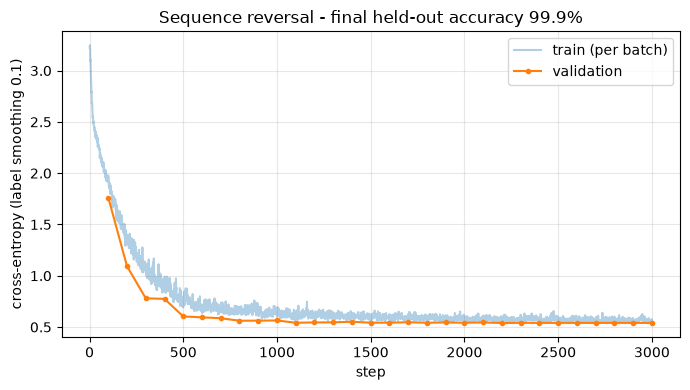

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(train_hist) + 1), train_hist, alpha=0.35, label="train (per batch)")
ax.plot(*zip(*val_hist), marker="o", ms=3, label="validation")
ax.set(xlabel="step", ylabel="cross-entropy (label smoothing 0.1)",
       title=f"Sequence reversal - final held-out accuracy {acc:.1%}")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "loss_curve.png", dpi=150)
plt.show()

## 11. 图 2：交叉注意力热力图

画的是**最后一层解码器的交叉注意力**：每一行是解码器的一步（“→ 8”表示这一步输出 8），每一列是一个输入数字，颜色越亮表示越关注。

**预期**：输出第 1 个数字时看输入的最后一位，输出第 2 个时看倒数第二位……所以亮格连成一条从右上到左下的**反对角线**。
最后一行 `EOS` 比较分散，因为判断“该结束了”不需要盯着某一个具体数字。

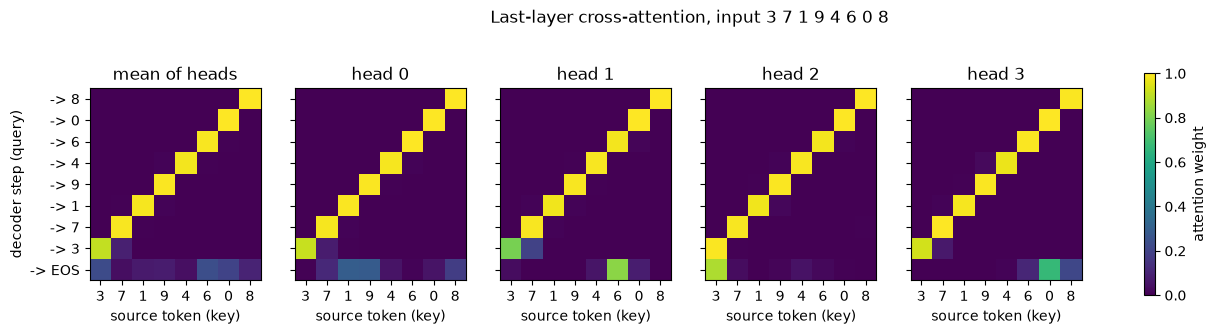

In [18]:
digits = [3, 7, 1, 9, 4, 6, 0, 8]
src = torch.tensor([[d + DIGIT0 for d in digits]], device=device)
with torch.no_grad():
    pred = greedy_decode(model, src)[0, :len(digits) + 1]
    tgt_in = torch.cat([torch.tensor([BOS], device=device), pred[:-1]])[None]
    model(src, tgt_in)
w = model.decoders[-1].cross_attn.last_weights[0].cpu()   # [heads, tgt, src]

name = lambda t: {BOS: "BOS", EOS: "EOS"}.get(t, str(t - DIGIT0))
ylabels = [f"-> {name(t)}" for t in pred.tolist()]   # what each query row predicts
xlabels = [str(d) for d in digits]

panels = [("mean of heads", w.mean(0))] + [(f"head {h}", w[h]) for h in range(w.size(0))]
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.6))
for ax, (title, m) in zip(axes, panels):
    im = ax.imshow(m, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(len(xlabels)), xlabels)
    ax.set_yticks(range(len(ylabels)), ylabels if ax is axes[0] else [])
    ax.set_xlabel("source token (key)")
axes[0].set_ylabel("decoder step (query)")
fig.colorbar(im, ax=axes, shrink=0.8, label="attention weight")
fig.suptitle(f"Last-layer cross-attention, input {' '.join(xlabels)}")
fig.savefig(OUT / "attention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. 图 3：3D Loss 地形 + 梯度下降轨迹

模型有约 17 万个参数，loss 是一个 17 万维空间上的函数，没法直接画。做法（Li et al. 2018）：

1. 训练时每 100 步存下的参数快照，构成一条“训练轨迹”。
2. 对轨迹做 **PCA**，找出参数变化最大的两个方向 PC1、PC2。
3. 以最终参数为原点，在 PC1–PC2 平面上取 31×31 个点，每个点把参数设成 `最终参数 + a·PC1 + b·PC2`，算验证集 loss → 得到曲面。
4. 把轨迹投影到这个平面上，画成红线。

**注意（简化）**：这只是 17 万维空间中的一个二维**切片**。两个方向只解释了轨迹的大部分变化，所以红线起点在图上的 loss（约 1.3）和真实初始 loss（约 3.2）对不上——差的那部分在被投影掉的方向里。

In [19]:
@torch.no_grad()
def landscape(model, snapshots, n=31, pad=0.25):
    params = list(model.parameters())
    final = parameters_to_vector(params).clone()
    offsets = torch.stack(snapshots) - final                  # [T, P], relative to final weights
    _, s, vh = torch.linalg.svd(offsets, full_matrices=False)
    dirs = vh[:2]                                              # two orthonormal directions
    explained = (s[:2] ** 2 / (s ** 2).sum()).tolist()
    path = offsets @ dirs.T                                    # trajectory projected onto the plane

    def loss_at(a, b):
        vector_to_parameters(final + a * dirs[0] + b * dirs[1], params)
        return loss_on(model, val_src, val_tgt).item()

    lo, hi = path.min(0).values, path.max(0).values
    span = hi - lo
    xs = torch.linspace(lo[0] - pad * span[0], hi[0] + pad * span[0], n)
    ys = torch.linspace(lo[1] - pad * span[1], hi[1] + pad * span[1], n)
    zs = torch.tensor([[loss_at(x, y) for x in xs] for y in ys])
    path_z = [loss_at(a, b) for a, b in path.tolist()]
    vector_to_parameters(final, params)                       # restore trained weights
    return xs, ys, zs, path.cpu(), path_z, explained


model.eval()
xs, ys, zs, path, path_z, explained = landscape(model, snapshots)
print(f"PC1 explains {explained[0]:.0%}, PC2 explains {explained[1]:.0%} of the path variance")

PC1 explains 79%, PC2 explains 10% of the path variance


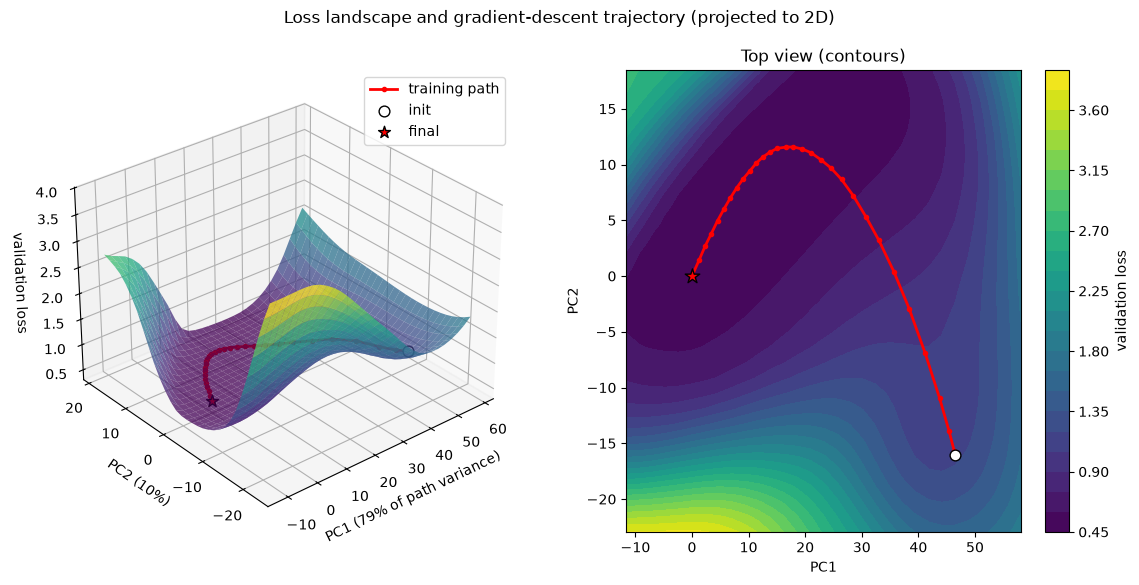

In [20]:
X, Y = torch.meshgrid(xs, ys, indexing="xy")
px, py = path[:, 0], path[:, 1]
fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X, Y, zs, cmap="viridis", alpha=0.75, linewidth=0)
ax.plot(px, py, path_z, color="red", marker="o", ms=3, lw=2, label="training path")
ax.scatter(px[0], py[0], path_z[0], color="white", edgecolor="k", s=60, label="init")
ax.scatter(px[-1], py[-1], path_z[-1], color="red", edgecolor="k", s=80, marker="*", label="final")
ax.set(xlabel=f"PC1 ({explained[0]:.0%} of path variance)",
       ylabel=f"PC2 ({explained[1]:.0%})", zlabel="validation loss")
ax.view_init(elev=30, azim=-130)
ax.legend()
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contourf(X, Y, zs, levels=30, cmap="viridis")
ax2.plot(px, py, color="red", marker="o", ms=3, lw=2)
ax2.scatter(px[0], py[0], color="white", edgecolor="k", s=60, zorder=3)
ax2.scatter(px[-1], py[-1], color="red", edgecolor="k", s=120, marker="*", zorder=3)
ax2.set(xlabel="PC1", ylabel="PC2", title="Top view (contours)")
fig.colorbar(cs, ax=ax2, label="validation loss")
fig.suptitle("Loss landscape and gradient-descent trajectory (projected to 2D)")
fig.savefig(OUT / "loss_landscape_3d.png", dpi=150, bbox_inches="tight")
plt.show()